# Phase 2 — Association Rule Mining and Recommendation Evaluation

**Project:** Basketly — Market Basket Analysis and Product Recommendation System

This notebook documents the Phase 2 experiments using the result files already generated by the project. It compares Apriori and FP-Growth, studies parameter sensitivity, examines discovered association rules, and evaluates popularity-based, association-rule and hybrid recommendations.

> **Reproducibility:** Run this notebook from the repository root. It reads the saved CSV and JSON outputs under `backend/data/processed/`; it does not rerun the original mining or recommendation experiments.

## 1. Objectives

1. Compare Apriori and FP-Growth using the same transaction data and mining thresholds.
2. Examine how minimum support and minimum confidence affect the number of rules.
3. Inspect representative frequent itemsets and association rules.
4. Evaluate recommendation methods using the saved held-out evaluation results.
5. Compare a separate basket-completion experiment and discuss the limitations of the evaluation protocols.

In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find repository root automatically
CURRENT = Path.cwd()
ROOT = None

for folder in [CURRENT] + list(CURRENT.parents):
    if (folder / "backend" / "data" / "processed").exists():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate backend/data/processed. "
        "Please open the correct project folder in VS Code."
    )

RESULTS = ROOT / "backend" / "data" / "processed"

def load_json(relative_path):
    path = RESULTS / relative_path
    with path.open("r", encoding="utf-8") as file:
        return json.load(file)

def load_csv(relative_path):
    path = RESULTS / relative_path
    return pd.read_csv(path)

print("Repository root:", ROOT.resolve())
print("Results directory:", RESULTS.resolve())

Repository root: D:\Semester 7\Data Science\DS Project
Results directory: D:\Semester 7\Data Science\DS Project\backend\data\processed


## 2. Association mining setup

The saved mining statistics describe 30,000 transactions. The preprocessing and support threshold retain a subset of products before mining. Both algorithms were evaluated using the same selected thresholds:

- Minimum support: **0.005**
- Minimum confidence: **0.20**
- Minimum lift: **1.0**
- Maximum itemset length: **3**

Support is the fraction of transactions containing an itemset. Confidence measures how often the consequent appears when the antecedent appears. Lift compares that co-occurrence against what would be expected if the two sides were independent; a lift greater than 1 indicates a positive association.

In [2]:
apriori_stats = load_json("association_mining/apriori_statistics.json")
fpgrowth_stats = load_json("association_mining/fpgrowth_statistics.json")

mining_summary = pd.DataFrame([
    {"Algorithm": "Apriori", **apriori_stats},
    {"Algorithm": "FP-Growth", **fpgrowth_stats},
])

display(mining_summary.set_index("Algorithm"))

,transactions,products_before_filtering,products_after_filtering,minimum_basket_count,frequent_itemset_count,association_rule_count,min_support,min_confidence,min_lift,max_len
Algorithm,,,,,,,,,,
Apriori,30000,24876,252,150,335,49,0.005,0.2,1.0,3
FP-Growth,30000,24876,252,150,335,49,0.005,0.2,1.0,3


### 2.1 Apriori and FP-Growth output comparison

The saved statistics report the same number of retained products, frequent itemsets and association rules for both algorithms under the selected configuration. The parameter-sensitivity experiment below also records their measured runtimes.

In [3]:
apriori_itemsets = load_csv("association_mining/apriori_frequent_itemsets.csv")
fpgrowth_itemsets = load_csv("association_mining/fpgrowth_frequent_itemsets.csv")
apriori_rules = load_csv("association_mining/apriori_association_rules.csv")
fpgrowth_rules = load_csv("association_mining/fpgrowth_association_rules.csv")

print("Apriori frequent itemsets:", len(apriori_itemsets))
print("FP-Growth frequent itemsets:", len(fpgrowth_itemsets))
print("Apriori rules:", len(apriori_rules))
print("FP-Growth rules:", len(fpgrowth_rules))

print("\nTop frequent itemsets (Apriori output):")
display(apriori_itemsets.head(10))

print("\nTop association rules (FP-Growth output):")
display(fpgrowth_rules.head(10))

Apriori frequent itemsets: 335
FP-Growth frequent itemsets: 335
Apriori rules: 49
FP-Growth rules: 49

Top frequent itemsets (Apriori output):


,product_ids,product_names,itemset_length,support
0,24852,Banana,1,0.143667
1,13176,Bag of Organic Bananas,1,0.116933
2,21137,Organic Strawberries,1,0.083900
3,21903,Organic Baby Spinach,1,0.077300
4,47209,Organic Hass Avocado,1,0.067600
5,47766,Organic Avocado,1,0.053233
6,47626,Large Lemon,1,0.048667
7,26209,Limes,1,0.044367
8,27845,Organic Whole Milk,1,0.043500
9,16797,Strawberries,1,0.042233



Top association rules (FP-Growth output):


,antecedent_ids,antecedent_names,consequent_ids,consequent_names,support,confidence,lift,leverage,conviction
0,24964,Organic Garlic,22935,Organic Yellow Onion,0.008033,0.239325,6.485765,0.006795,1.266112
1,22935,Organic Yellow Onion,24964,Organic Garlic,0.008033,0.217706,6.485765,0.006795,1.235383
2,31717,Organic Cilantro,26209,Limes,0.005433,0.256289,5.776619,0.004493,1.284953
3,26209,Limes,47626,Large Lemon,0.010000,0.225394,4.631393,0.007841,1.228152
4,47626,Large Lemon,26209,Limes,0.010000,0.205479,4.631393,0.007841,1.202780
5,13176|21137,Bag of Organic Bananas | Organic Strawberries,47209,Organic Hass Avocado,0.005000,0.259965,3.845641,0.003700,1.259941
6,30391,Organic Cucumber,47209,Organic Hass Avocado,0.006300,0.259615,3.840464,0.004660,1.259345
7,5876,Organic Lemon,47209,Organic Hass Avocado,0.006733,0.246944,3.653014,0.004890,1.238155
8,21137|47209,Organic Strawberries | Organic Hass Avocado,13176,Bag of Organic Bananas,0.005000,0.383632,3.280773,0.003476,1.432693
9,27966,Organic Raspberries,21137,Organic Strawberries,0.010767,0.256961,3.062706,0.007251,1.232910


## 3. Parameter sensitivity analysis

The experiment varies:

- Minimum support: **0.003, 0.005, 0.010**
- Minimum confidence: **0.20, 0.30, 0.40**

This gives 9 threshold combinations for each algorithm, or 18 recorded runs in total. Minimum lift is 1.0 and maximum itemset length is 3 throughout.

A higher minimum support filters out less frequent products and itemsets. A higher minimum confidence makes the rule-generation condition stricter, generally reducing the number of retained rules.

In [4]:
sensitivity = load_csv("parameter_sensitivity/sensitivity_results.csv")

print("Recorded experiment rows:", len(sensitivity))
display(
    sensitivity.sort_values(
        ["min_support", "min_confidence", "algorithm"]
    ).reset_index(drop=True)
)

Recorded experiment rows: 18


,experiment,algorithm,min_support,min_confidence,min_lift,max_len,products_retained,minimum_basket_count,frequent_itemsets,association_rules,runtime_seconds
0,1,apriori,0.003,0.2,1.0,3,513,90,795,138,2.3002
1,1,fpgrowth,0.003,0.2,1.0,3,513,90,795,138,1.3480
2,2,apriori,0.003,0.3,1.0,3,513,90,795,22,2.4884
3,2,fpgrowth,0.003,0.3,1.0,3,513,90,795,22,1.2598
4,3,apriori,0.003,0.4,1.0,3,513,90,795,2,2.2383
5,3,fpgrowth,0.003,0.4,1.0,3,513,90,795,2,1.4232
6,4,apriori,0.005,0.2,1.0,3,252,150,335,49,0.9622
7,4,fpgrowth,0.005,0.2,1.0,3,252,150,335,49,0.8374
8,5,apriori,0.005,0.3,1.0,3,252,150,335,6,0.9126
9,5,fpgrowth,0.005,0.3,1.0,3,252,150,335,6,0.8562


algorithm                   apriori  fpgrowth
min_support min_confidence                   
0.003       0.2              2.3002    1.3480
            0.3              2.4884    1.2598
            0.4              2.2383    1.4232
0.005       0.2              0.9622    0.8374
            0.3              0.9126    0.8562
            0.4              0.8938    0.8269
0.010       0.2              0.4669    0.4806
            0.3              0.3661    0.4767
            0.4              0.3593    0.4134

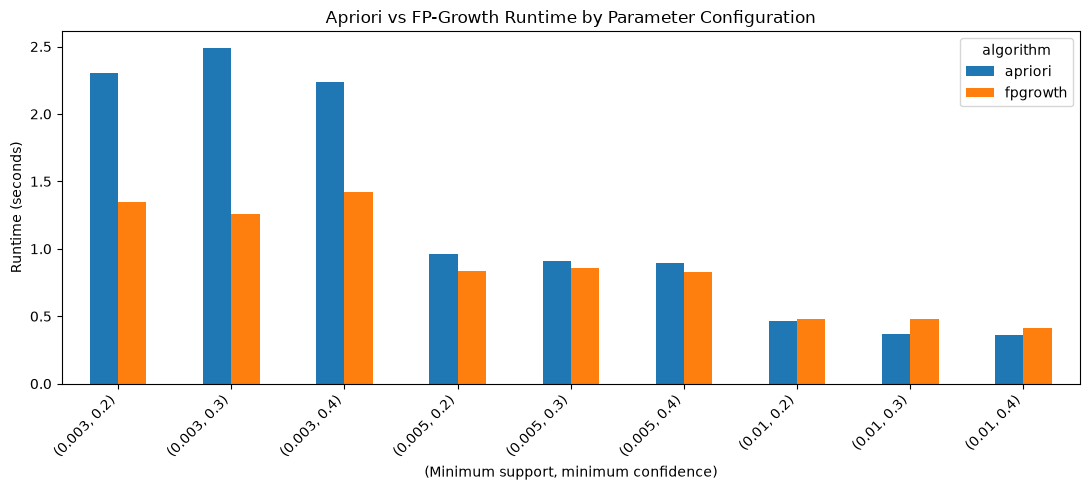

In [5]:
# Compare algorithm runtimes across all tested configurations.
runtime_pivot = sensitivity.pivot_table(
    index=["min_support", "min_confidence"],
    columns="algorithm",
    values="runtime_seconds"
)

display(runtime_pivot)

runtime_pivot.plot(kind="bar", figsize=(11, 5))
plt.title("Apriori vs FP-Growth Runtime by Parameter Configuration")
plt.xlabel("(Minimum support, minimum confidence)")
plt.ylabel("Runtime (seconds)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

algorithm                   apriori  fpgrowth
min_support min_confidence                   
0.003       0.2               138.0     138.0
            0.3                22.0      22.0
            0.4                 2.0       2.0
0.005       0.2                49.0      49.0
            0.3                 6.0       6.0
            0.4                 0.0       0.0
0.010       0.2                15.0      15.0
            0.3                 3.0       3.0
            0.4                 0.0       0.0

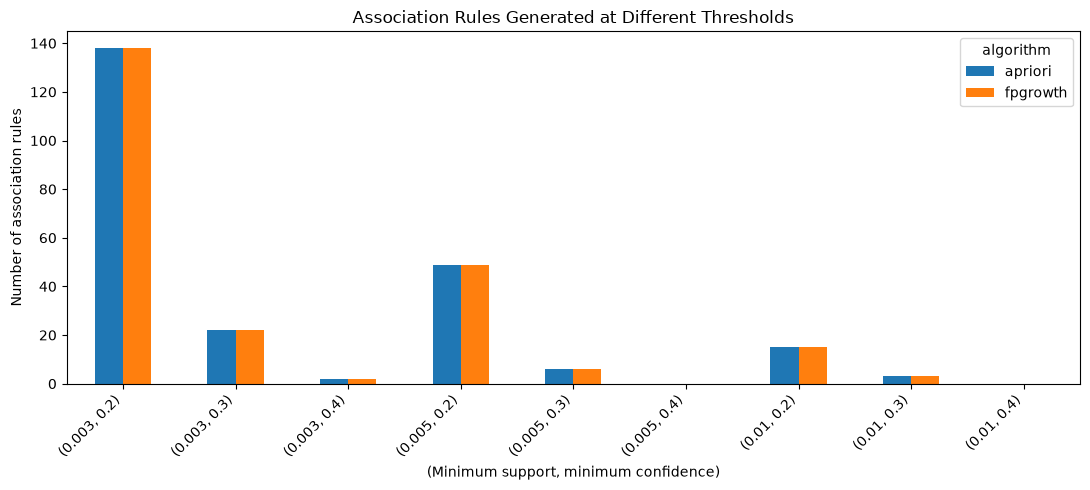

In [6]:
# Show how minimum confidence changes the number of generated rules.
rule_pivot = sensitivity.pivot_table(
    index=["min_support", "min_confidence"],
    columns="algorithm",
    values="association_rules"
)

display(rule_pivot)

rule_pivot.plot(kind="bar", figsize=(11, 5))
plt.title("Association Rules Generated at Different Thresholds")
plt.xlabel("(Minimum support, minimum confidence)")
plt.ylabel("Number of association rules")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 3.1 Interpretation

Use the displayed results to discuss the trade-off between the thresholds and the number of discovered rules. At the selected support of 0.005 and confidence of 0.20, the sensitivity results report 335 frequent itemsets and 49 rules for each algorithm. Increasing confidence reduces the number of rules while leaving the frequent-itemset count unchanged in these saved experiments.

Runtime is hardware- and environment-dependent; the measured values should be interpreted as observations from this run, not universal performance guarantees.

## 4. Association-rule examples

The rule table contains antecedents, consequents, support, confidence and lift. These metrics help rank potentially useful product relationships, but a high lift or confidence does not by itself prove causation.

In [7]:
rules = fpgrowth_rules.copy()
display(
    rules.sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    ).head(15)
)

,antecedent_ids,antecedent_names,consequent_ids,consequent_names,support,confidence,lift,leverage,conviction
0,24964,Organic Garlic,22935,Organic Yellow Onion,0.008033,0.239325,6.485765,0.006795,1.266112
1,22935,Organic Yellow Onion,24964,Organic Garlic,0.008033,0.217706,6.485765,0.006795,1.235383
2,31717,Organic Cilantro,26209,Limes,0.005433,0.256289,5.776619,0.004493,1.284953
3,26209,Limes,47626,Large Lemon,0.010000,0.225394,4.631393,0.007841,1.228152
4,47626,Large Lemon,26209,Limes,0.010000,0.205479,4.631393,0.007841,1.202780
5,13176|21137,Bag of Organic Bananas | Organic Strawberries,47209,Organic Hass Avocado,0.005000,0.259965,3.845641,0.003700,1.259941
6,30391,Organic Cucumber,47209,Organic Hass Avocado,0.006300,0.259615,3.840464,0.004660,1.259345
7,5876,Organic Lemon,47209,Organic Hass Avocado,0.006733,0.246944,3.653014,0.004890,1.238155
8,21137|47209,Organic Strawberries | Organic Hass Avocado,13176,Bag of Organic Bananas,0.005000,0.383632,3.280773,0.003476,1.432693
9,27966,Organic Raspberries,21137,Organic Strawberries,0.010767,0.256961,3.062706,0.007251,1.232910


## 5. Recommendation evaluation — per-user held-out basket

This evaluation uses the saved per-user protocol:

- 30,000 sampled baskets in total.
- 3,414 held-out baskets/users.
- 3,320 evaluated cases (some held-out baskets have no relevant new products after excluding products already in the latest training basket).
- For each eligible user, the latest observed sampled basket by original order number is held out; the other sampled baskets are used for training.

**Important limitation:** the source data is a deterministic random sample of prior orders. The held-out basket is the latest *observed sampled* basket for that user, not necessarily the user's next consecutive real-world basket. This is not a global chronological split across all users.

In [8]:
per_user_summary = load_json(
    "per_user_recommendation_evaluation/recommendation_summary.json"
)

print("Evaluation method:", per_user_summary["evaluation_method"])
print("Description:", per_user_summary["description"])
print("Limitation:", per_user_summary["important_limitation"])

per_user_metrics = pd.DataFrame(per_user_summary["results"])
display(per_user_metrics)

Evaluation method: Per-user leave-last-observed-sampled-basket-out
Description: For each user with at least two sampled baskets, the latest sampled basket by original order_number is held out. All other sampled baskets are used for training.
Limitation: The source dataset is a deterministic random sample of prior orders. The held-out basket is the latest observed sampled basket, not necessarily the user's next consecutive real-world basket. This is not a global chronological split across users.


,method,k,precision_at_k,recall_at_k,hit_rate_at_k,evaluated_cases
0,popularity,5,0.0694,0.0464,0.2861,3320
1,popularity,10,0.0538,0.0680,0.3786,3320
2,rules,5,0.0182,0.0111,0.0861,3320
3,rules,10,0.0091,0.0111,0.0861,3320
4,hybrid,5,0.0703,0.0469,0.2898,3320
5,hybrid,10,0.0540,0.0683,0.3801,3320


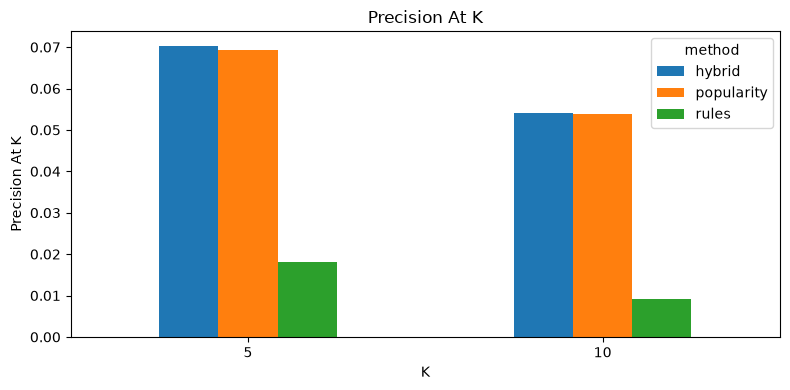

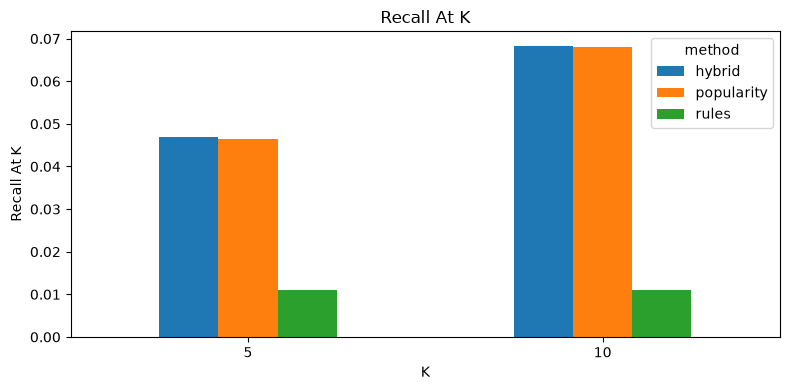

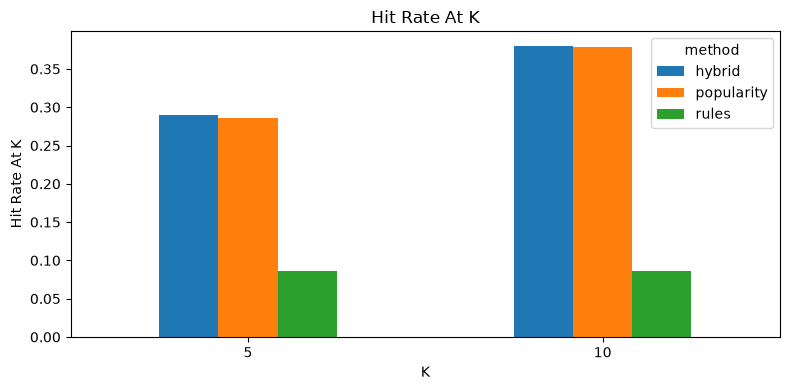

In [9]:
# Compare precision, recall and hit rate at K for the per-user protocol.
for metric in ["precision_at_k", "recall_at_k", "hit_rate_at_k"]:
    pivot = per_user_metrics.pivot(
        index="k", columns="method", values=metric
    )
    ax = pivot.plot(kind="bar", figsize=(8, 4))
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("K")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

### 5.1 Interpretation of the per-user results

Compare the hybrid method with the popularity baseline at K=5 and K=10. The saved results show the hybrid method slightly ahead on all three reported metrics at these cutoffs. The association-rule-only method is lower on this particular evaluation, which indicates that rule candidates alone are relatively sparse and do not cover as many relevant products.

The hybrid approach combines rule-based candidates with popularity-based fallback recommendations. This helps provide recommendations when no applicable association-rule candidates are available.

## 6. Recommendation evaluation — larger held-out comparison

A separate saved evaluation compares popularity, association-rule and hybrid methods at K=5, 10 and 20 over 3,414 held-out users. This is the evaluation represented by `hybrid_comparison_summary.json` and `hybrid_comparison_metrics.csv`.

Do not combine its values with the preceding per-user summary: the saved summaries represent distinct evaluation outputs and report different evaluated-case counts and metric values.

In [10]:
hybrid_summary = load_json(
    "hybrid_recommendation_evaluation/hybrid_comparison_summary.json"
)
hybrid_metrics = load_csv(
    "hybrid_recommendation_evaluation/hybrid_comparison_metrics.csv"
)

overview_fields = [
    "training_baskets",
    "test_baskets",
    "test_users",
    "rules_mined",
    "users_with_activated_rules",
    "users_with_rule_recommendations",
    "users_with_hybrid_recommendations",
    "rule_activation_coverage",
    "rule_recommendation_coverage",
    "hybrid_recommendation_coverage",
]
display(pd.DataFrame(
    {"Measure": overview_fields,
     "Value": [hybrid_summary[field] for field in overview_fields]}
))

display(hybrid_metrics)

,Measure,Value
0,training_baskets,26586.000000
1,test_baskets,3414.000000
2,test_users,3414.000000
3,rules_mined,41.000000
4,users_with_activated_rules,1795.000000
5,users_with_rule_recommendations,1635.000000
6,users_with_hybrid_recommendations,3414.000000
7,rule_activation_coverage,0.525776
8,rule_recommendation_coverage,0.478910
9,hybrid_recommendation_coverage,1.000000


,method,k,precision_at_k,recall_at_k,hit_rate_at_k
0,popularity,5,0.067487,0.045131,0.278266
1,popularity,10,0.052314,0.066081,0.368190
2,popularity,20,0.039690,0.100147,0.459871
3,association_rules,5,0.017692,0.010768,0.083773
4,association_rules,10,0.008846,0.010768,0.083773
5,association_rules,20,0.004423,0.010768,0.083773
6,hybrid,5,0.068366,0.045625,0.281781
7,hybrid,10,0.052519,0.066397,0.369654
8,hybrid,20,0.039690,0.100147,0.459871


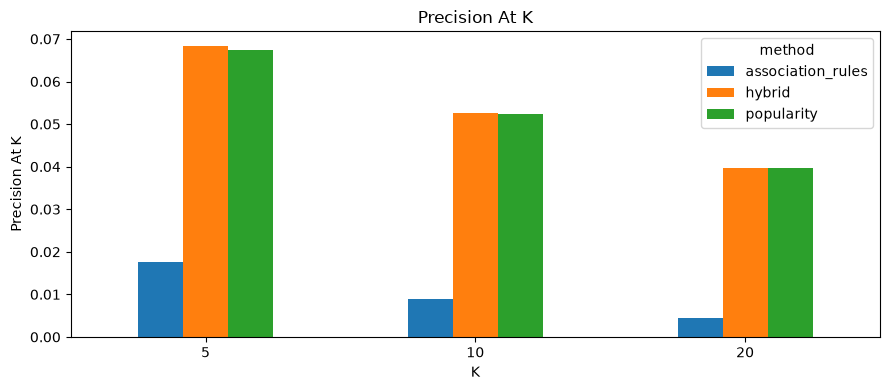

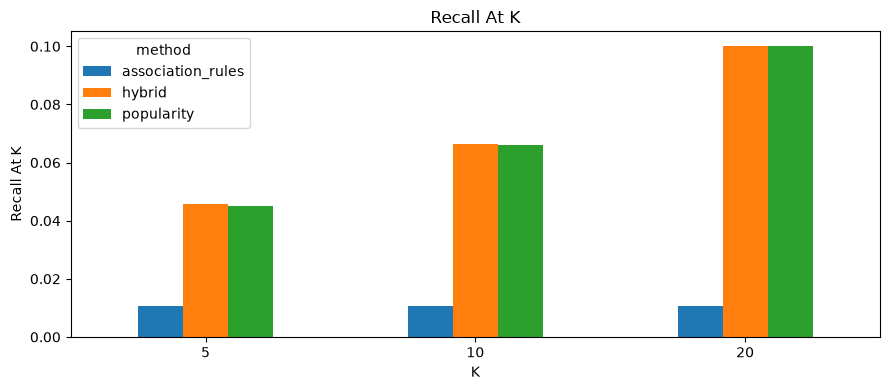

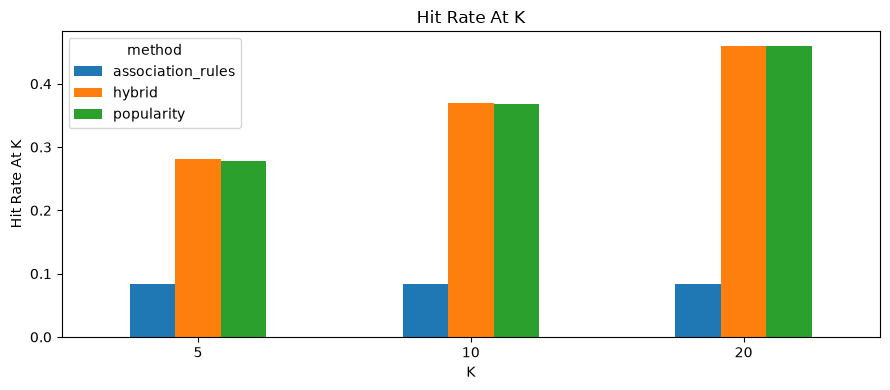

In [11]:
for metric in ["precision_at_k", "recall_at_k", "hit_rate_at_k"]:
    pivot = hybrid_metrics.pivot(
        index="k", columns="method", values=metric
    )
    ax = pivot.plot(kind="bar", figsize=(9, 4))
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("K")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

### 6.1 Hybrid recommendation strategy

The saved hybrid evaluation describes this ranking strategy:

1. Association-rule confidence, descending.
2. Association-rule lift, descending.
3. Association-rule support, descending.
4. Product ID, ascending, to break rule-ranking ties.
5. Popularity-based basket frequency, descending, for fallback candidates.
6. Product ID, ascending, to break popularity ties.

Products already present in the user's latest training basket are excluded. The saved summary reports 52.58% rule-activation coverage, 47.89% rule-recommendation coverage and 100% hybrid recommendation coverage because popularity fallback supplies candidates when rule recommendations are unavailable.

Coverage means that the system can produce recommendations; it does not mean that every recommendation is relevant or will be purchased.

## 7. Separate basket-completion experiment

The basket-completion evaluation uses a different protocol: a random 80/20 basket split, followed by hiding half of each test basket and treating the other half as the cart context. The saved summary reports 24,000 training baskets and 4,943 test cases.

These results should be interpreted separately from the per-user held-out-basket evaluations above because the data split and prediction task are different.

In [12]:
basket_completion_summary = load_json(
    "basket_completion_evaluation/basket_completion_summary.json"
)
basket_completion = load_csv(
    "basket_completion_evaluation/basket_completion_results.csv"
)

display(pd.DataFrame(
    {"Measure": list(basket_completion_summary.keys()),
     "Value": list(basket_completion_summary.values())}
))
display(basket_completion)

,Measure,Value
0,protocol,random 80/20 basket split; half of each test b...
1,seed,42
2,train_baskets,24000
3,test_cases,4943
4,rules_mined,50
5,k_values,"[5, 10, 20]"


,method,k,precision_at_k,recall_at_k,hit_rate_at_k
0,popularity,5,0.0590,0.0545,0.2531
1,popularity,10,0.0426,0.0773,0.3322
2,popularity,20,0.0300,0.1083,0.4178
3,rules,5,0.0204,0.0160,0.0953
4,rules,10,0.0102,0.0161,0.0953
5,rules,20,0.0051,0.0161,0.0953
6,hybrid,5,0.0598,0.0550,0.2575
7,hybrid,10,0.0429,0.0778,0.3346
8,hybrid,20,0.0300,0.1083,0.4178


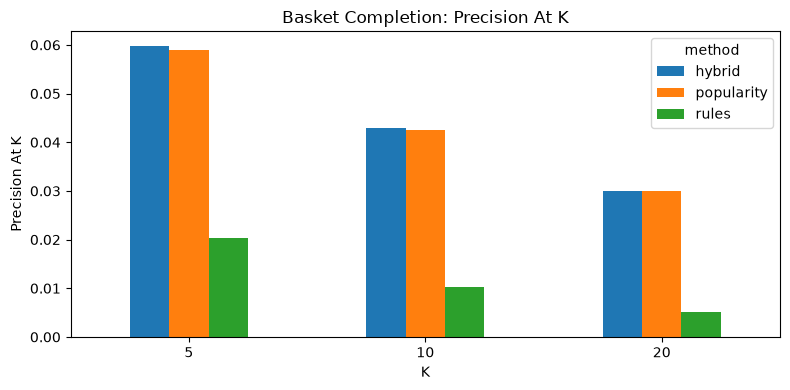

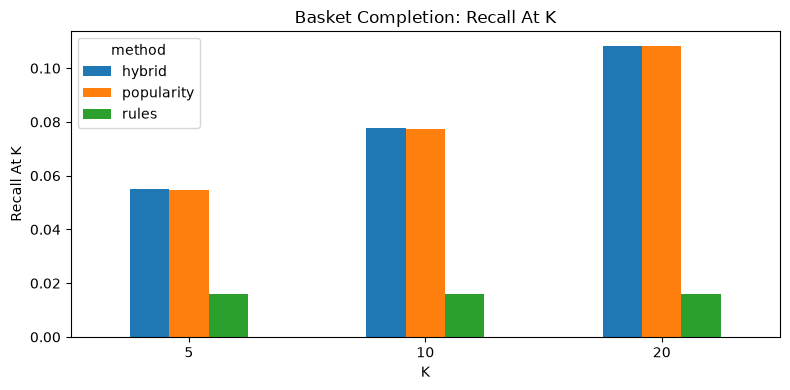

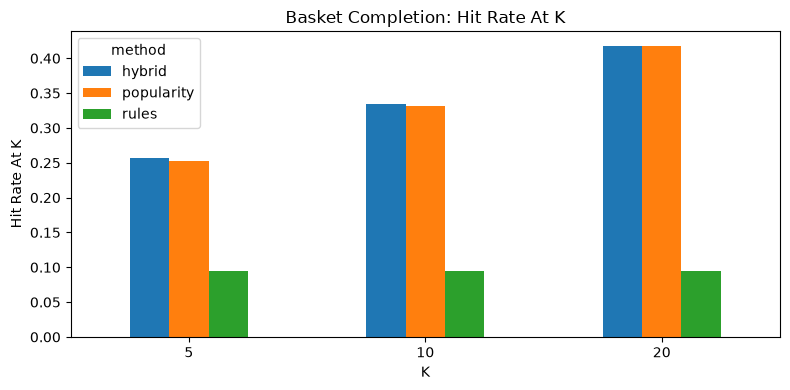

In [13]:
for metric in ["precision_at_k", "recall_at_k", "hit_rate_at_k"]:
    pivot = basket_completion.pivot(
        index="k", columns="method", values=metric
    )
    ax = pivot.plot(kind="bar", figsize=(8, 4))
    ax.set_title("Basket Completion: " + metric.replace("_", " ").title())
    ax.set_xlabel("K")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

## 8. Overall findings

Based on the saved experiments:

- Apriori and FP-Growth produced matching frequent-itemset and rule counts under the selected mining thresholds.
- The sensitivity experiment shows that increasing minimum confidence substantially reduces the number of generated rules.
- FP-Growth was faster than Apriori in several tested configurations, although the measured difference varies by configuration.
- Association rules reveal interpretable product relationships, but rule-only recommendations have limited coverage and lower top-K metrics in the saved recommendation comparisons.
- The hybrid method improves coverage by using popularity as a fallback and performs slightly better than popularity alone in the saved per-user evaluation at K=5 and K=10.
- Evaluation results depend on the split protocol. The per-user held-out sampled-basket evaluation and random basket-completion evaluation answer different questions and must be reported separately.

## 9. Limitations

1. The source data is a sample of prior grocery orders; results may not generalize to all customers or stores.
2. The latest sampled basket is not necessarily the user's next real-world order.
3. Association rules capture co-occurrence, not causation.
4. Popularity fallback can improve recommendation coverage while still producing irrelevant recommendations for an individual user.
5. Runtime measurements depend on the machine, software versions and execution environment.
6. The evaluation metrics measure agreement with held-out basket contents; they do not directly measure user satisfaction, business impact or actual conversion.

## 10. Conclusion

The experiments demonstrate how frequent-itemset mining can be used to discover grocery purchasing patterns and how association rules can be integrated with a popularity baseline to form a practical recommendation strategy. The hybrid approach addresses the limited coverage of rule-only recommendations, while the evaluation results highlight the importance of clearly defining the test protocol and interpreting recommendation metrics in context.